# EmPath two cleaned deliverables

**1. Census blocks with environmental context. 2. Walking graph with environmental edge attributes.**

Run with **Python (EmPath)**. This notebook previews existing real outputs; rebuilding is optional. Canopy is cover, not time-specific shade. NOAA temperature is a shared regional scenario, not measured per block. No newly learned friction weights or new imagery-model inference are claimed.

In [1]:
from pathlib import Path
import os,sys,json
os.environ.pop('PROJ_DATA',None)
os.environ.pop('GDAL_DATA',None)
ROOT=Path.cwd()
if not (ROOT/'scripts/package_clean_deliverables.py').exists(): ROOT=ROOT.parent
assert (ROOT/'scripts/package_clean_deliverables.py').exists()
sys.path.insert(0,str(ROOT/'scripts'))
OUT=ROOT/'output/clean_deliverables'
print('Python:',sys.executable)


Python: /Users/nalinikantheti/Documents/ChatGPT/EmPath/.venv/bin/python


## 1 Inspect completion and quality

In [2]:
import pandas as pd
report_path=OUT/'quality_report.json'
if report_path.exists():
    report=json.loads(report_path.read_text())
    display(pd.DataFrame([{'item':k,'value':v} for k,v in report.items() if k not in ['weather','limitations']]))
    print('Limitations:')
    for note in report['limitations']:print('-',note)
else:
    print('Packaging not finished. Run the rebuild cell below after input cleaning.')

,item,value
0,created_utc,2026-11-12T03:29:43.725293+00:00
1,blocks,2862
2,graph_nodes,31372
3,graph_directed_edges,93452
4,blocks_with_canopy,2853
5,edges_with_canopy,93262
6,block_traffic_matches,2862
7,edge_traffic_matches,93452
8,missing_temperature_raster,True
9,walking_speed_mps_assumption,1.2


Limitations:
- Canopy source and coverage details in output/canopy_2021/source_metadata.json
- No time-specific shade or local temperature predictions.
- Nearest road within 1 km is context, not route-specific crossing safety.
- Traffic count year absent from service; extraction date not used as count year.
- Block midpoint ID does not represent full edge-block overlap.
- Raw graph topology retained; entrances and crossings are not yet validated.
- GeoAI inference not run; published canopy dataset is ML-derived, not newly inferred here.


## 2 Preview the merged maps

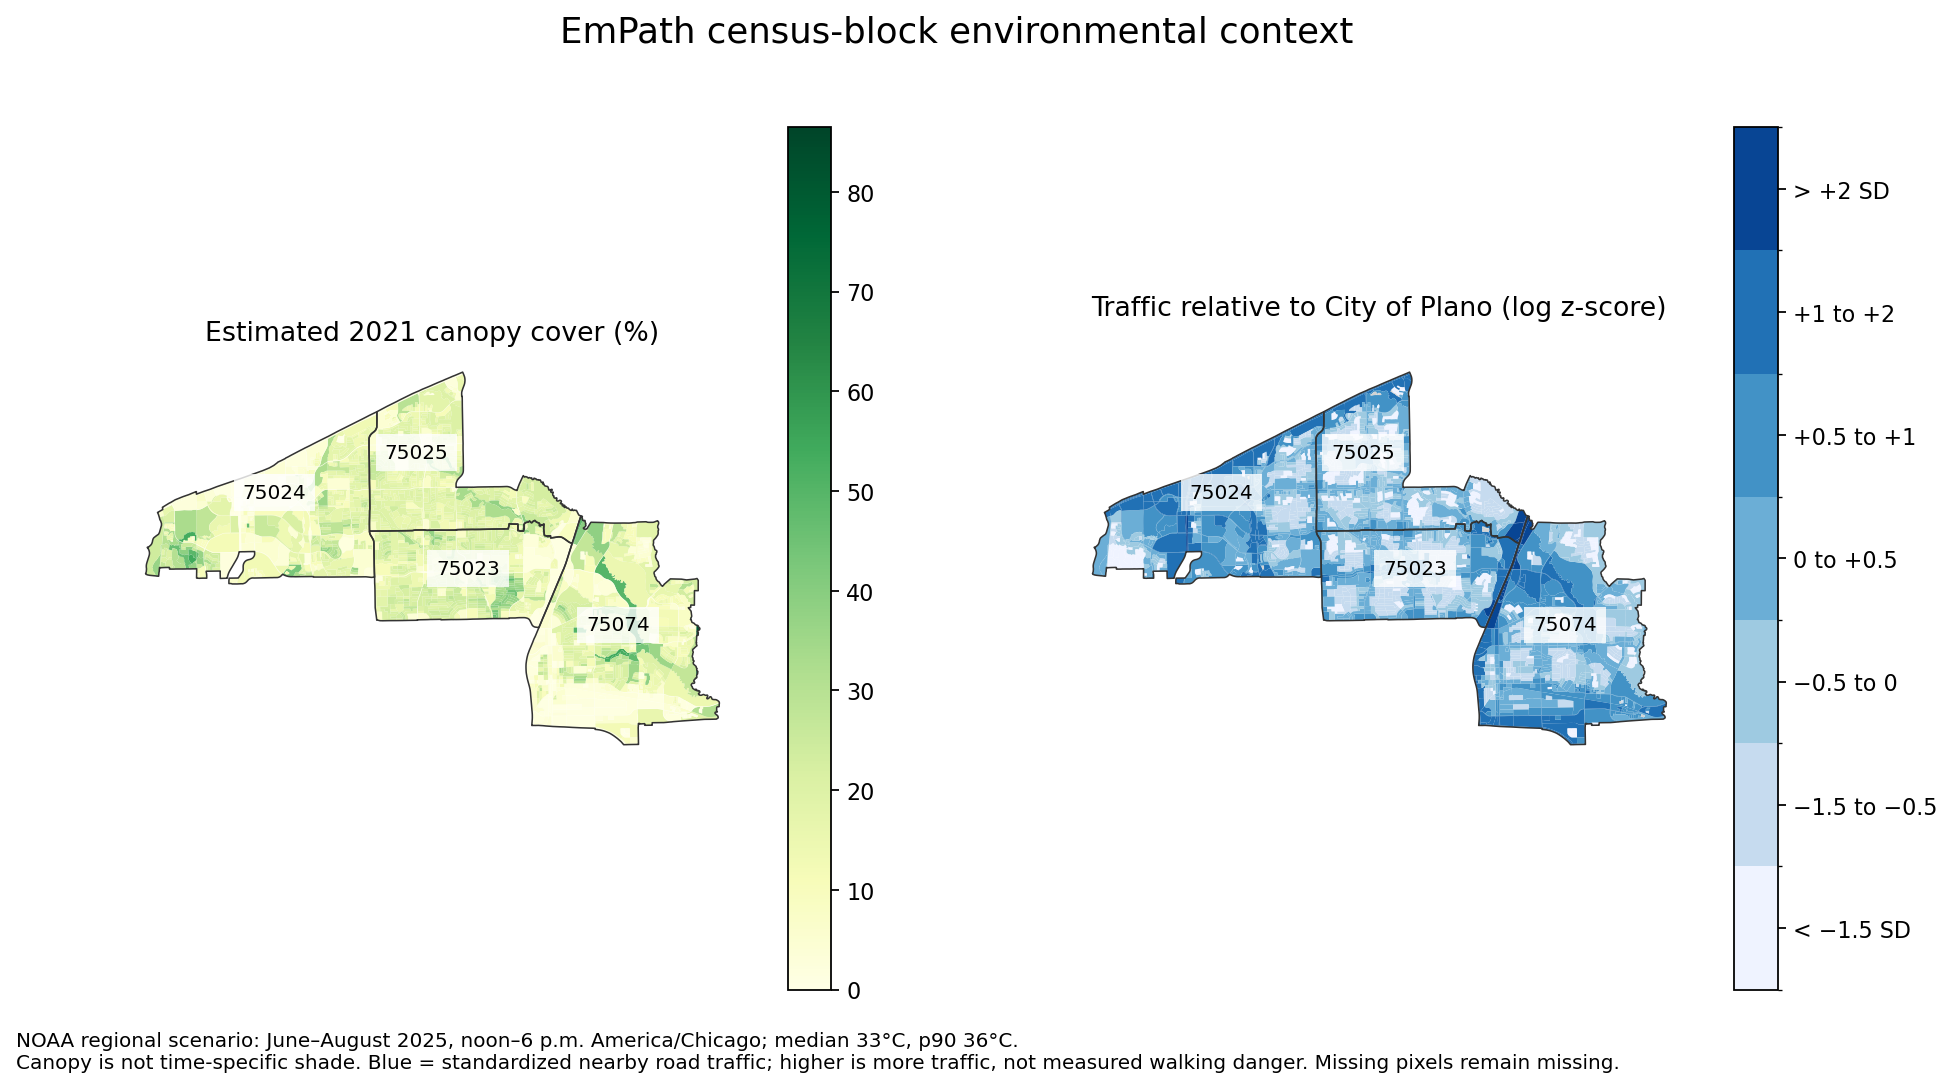

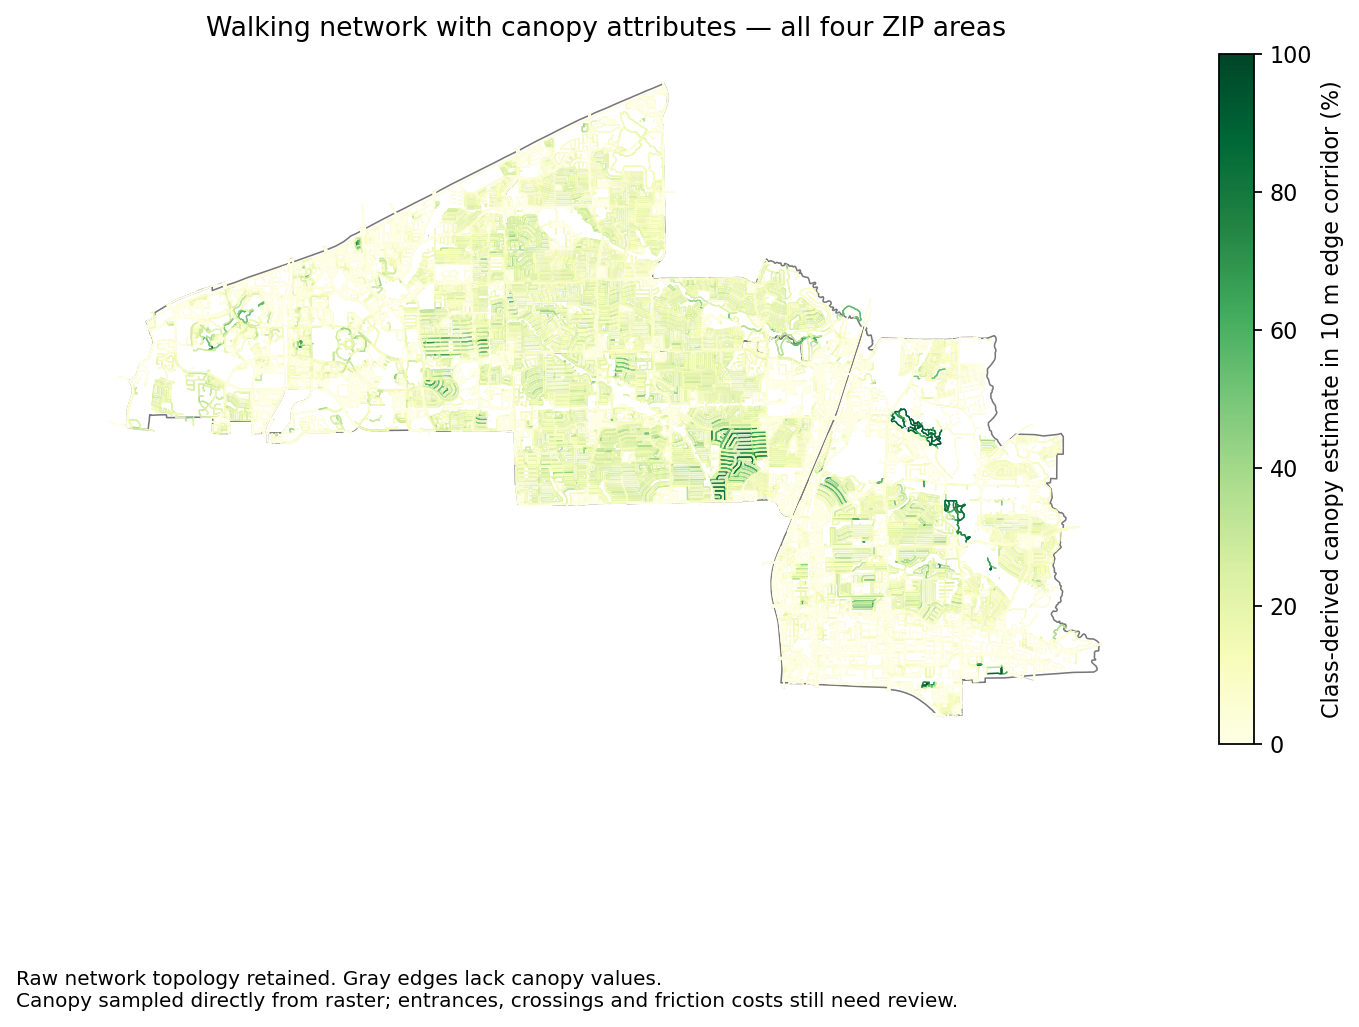

Map file: /Users/nalinikantheti/Documents/ChatGPT/EmPath/output/clean_deliverables/combined_environment_map.html


In [3]:
from IPython.display import display,Image,HTML
for name in ['block_environment_preview.png','walking_canopy_preview.png']:
    path=OUT/name
    if path.exists():display(Image(filename=str(path)))
path=OUT/'combined_environment_map.html'
if path.exists():
    display(HTML(f'<a href="{path.as_uri()}" target="_blank">Open interactive combined environment map</a>'))
    print('Map file:',path)

## 3 Inspect the block table

In [4]:
path=OUT/'block_environment.csv'
if path.exists():
    blocks=pd.read_csv(path,dtype={'GEOID20':str})
    fields=['GEOID20','canopy_mean','traffic_area_mean_aadt','traffic_area_max_aadt','traffic_z_raw','traffic_z_log','traffic_index_0_100']
    display(blocks[fields].head(12))
    print('Missing canopy:',blocks.canopy_mean.isna().sum())

,GEOID20,canopy_mean,traffic_area_mean_aadt,traffic_area_max_aadt,traffic_z_raw,traffic_z_log,traffic_index_0_100
0,480850320131001,1.760331,4133.733427,10289.0,-0.297870,0.156503,56.218190
1,480850320121008,21.206249,645.920443,3196.0,-0.468374,-0.977750,16.409909
2,480850316112014,0.906250,5436.059272,15957.0,-0.234205,0.323934,62.700598
3,480850316361000,18.524794,928.946895,3509.0,-0.454538,-0.755844,22.487142
4,480850316361006,19.730246,656.557416,3509.0,-0.467854,-0.967777,16.657782
5,480850316113013,17.472118,2155.283629,15957.0,-0.394588,-0.241587,40.454999
6,480850320122004,20.827660,1024.229221,3196.0,-0.449880,-0.696198,24.315230
7,480850320081041,0.000000,7696.433321,24321.0,-0.123705,0.536511,70.419741
8,480850320151000,7.230508,7607.402268,14433.0,-0.128057,0.529398,70.173519
9,480850313242046,1.267045,3798.379737,13418.0,-0.314264,0.104782,54.172563


Missing canopy: 9


## 4 Inspect the graph edge table
Join attributes using `(u,v,key)`, never row order. `block_geoid_midpoint` identifies the block at the midpoint; it does not allocate a crossing edge entirely to that block. Canopy values are sampled directly from the raster in edge corridors.

In [5]:
path=OUT/'walking_edge_attributes.csv'
if path.exists():
    edges=pd.read_csv(path,dtype={'block_geoid_midpoint':str})
    display(edges.head())
    assert not edges.duplicated(['u','v','key']).any()
    print('Directed edges:',len(edges))

,u,v,key,traffic_distance_m,nearest_mapped_road_aadt,traffic_source_id,traffic_context_matched,busy_road_threshold_aadt,busy_road_distance_m,nearest_busy_road_aadt,...,traffic_z_raw,traffic_z_log,traffic_index_0_100,canopy_mean,canopy_min,canopy_max,canopy_valid_pixels,canopy_zone_centers_in_raster,canopy_valid_center_fraction,canopy_raster_overlap_fraction
0,26453885,13103365094,0,0.000000,31894,496760,True,10000,0.000000,31894.0,...,2.623057,1.830505,96.641280,0.0,0.0,0.0,7,7,1.000000,1.0
1,26454012,1371470529,0,0.000000,138828,231706,True,10000,0.000000,138828.0,...,2.329398,1.770124,96.164672,0.0,0.0,0.0,17,22,0.772727,1.0
2,26454012,11752576347,0,1.610124,15509,511289,True,10000,1.610124,15509.0,...,2.462273,1.798186,96.392621,0.0,0.0,0.0,4,4,1.000000,1.0
3,26454012,11752576346,0,1.864594,15509,511289,True,10000,1.864594,15509.0,...,2.537953,1.813611,96.513121,0.0,0.0,0.0,4,4,1.000000,1.0
4,26454015,1371470516,0,0.000000,138828,231706,True,10000,0.000000,138828.0,...,2.347440,1.774010,96.196926,0.0,0.0,0.0,7,24,0.291667,1.0


Directed edges: 93452


## 5 Optional rebuild
This recomputes all edge summaries and may take several minutes. It uses current cached inputs; no automatic statewide download or model installation. To refresh municipal cleaning, NOAA, traffic or the canopy clip, use the commands in the output README first.

In [6]:
REBUILD=False
if REBUILD:
    import environment_pipeline as ep
    from package_clean_deliverables import main
    config=json.loads((ROOT/'config/environment_pipeline.json').read_text())
    ep.run(config)
    main()
else:
    print('Preview only. Set REBUILD=True only after editing input paths or data.')

Preview only. Set REBUILD=True only after editing input paths or data.


## What is still separate
- Validate selected entrances, crossings and example routes before showing routing recommendations.
- Define/calibrate friction costs after inspecting these attributes; no arbitrary combined score is hidden in cleaning.
- Optional SamGeo inference is in notebook 07; it still needs real RGB imagery and optional dependencies.
- Mapillary inspection requires API access and local coverage checks. APE is optional model-training data, not local environmental observations.
- See `output/clean_deliverables/README.md` for provenance and source status.

## Corrected traffic method
The blue block layer uses a length-weighted mean AADT across primary road portions within block + 100 m, followed by a City of Plano log z-score. It no longer picks one nearest road. The 0–100 index is a normal-CDF display transform, not measured danger. See `traffic_index_method.json` for reference parameters and buffer sensitivity.

## Find a block or trail
Click a block for its full GEOID, coordinates, Google Maps link and nearby Street View link. Zoom to level 16 or closer for block labels. Coordinates are a point inside the block, not a verified entrance/address.

The actual city traffic reference contains 4,387 valid blocks within the official Plano municipal polygon. The displayed pilot remains the four ZIP areas.

For shaded bike-path candidates, open `output/trail_finder/shaded_trail_candidates.html`; candidate CSV includes names, canopy and Google Maps links.

## Location and canopy interpretation check
Morada Plano is at 1009 14th Street. Its municipal address point falls in GEOID 480850319022006 (block code 2006), not a block identified by the street number 1009. The temporary Morada marker has been removed. Use block addresses for geographic lookup.

Texas canopy pixels are class codes. The pipeline now decodes the verified canopy key into explicit class-midpoint estimates; it no longer treats code 1 (Not tree) as 1% canopy. This is an approximate cover estimate, not measured shade. Traffic and canopy fills are mutually exclusive to prevent color blending.